In [1]:
import sys
!{sys.executable} -m pip install seaborn

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --------------- ------------------------ 3.7/9.5 MB 18.7 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.5 MB 15.8 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.5 MB 14.7 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 13.6 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------------------- -- 2.4/2.5 MB 12.6 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 11.4 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------- ----------------------------- 3.4/12.7 MB 16.8 MB/s eta 0:00:01
   -------------------- ------------------- 6.6/12.7 MB 15.9 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.7 MB 13.7 MB/s eta 0:00:01
   ------------------------------------ --- 11.5/12.7 MB 13.4 MB/s eta 0:00:01
   --------------------

In [2]:
import seaborn as sns
import pandas as pd
df = sns.load_dataset("titanic")

In [3]:
df.to_csv("titanic.csv",index=False)
df = pd.read_csv("titanic.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [4]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
df.shape

(891, 15)

In [6]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage = missing_percentage[missing_percentage > 0]
print(missing_percentage)

age            19.865320
embarked        0.224467
deck           77.216611
embark_town     0.224467
dtype: float64


In [7]:
df["age"]=df["age"].fillna(df["age"].median())


age has approximatly 19.87% of missing values,which falls in 5% to 30% of threshold.So the missing values will be imputed by the median value.Median imputation preserves the most of the dataset while reducing the influence of outliers

In [8]:
df=df.dropna(subset=["embarked"])
df=df.dropna(subset=["embark_town"])

embarked and embark_town has approximatly 0.22% of missing values,which falls in 0 to 5% of threshold.So we can drop the embarked and embark_town rows here dataloss is negligible.

In [9]:
df=df.drop(columns=["deck"])

deck has approximately 77.22% of the missing values ,which is above 30% of threshold.Imputing such large proportion would introduce substantial uncertanity,so the column was removed from dataset. 

In [10]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

univarent analysis

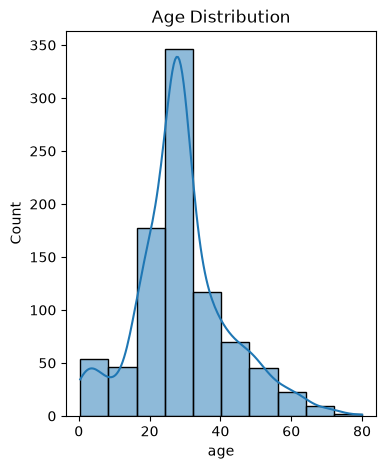

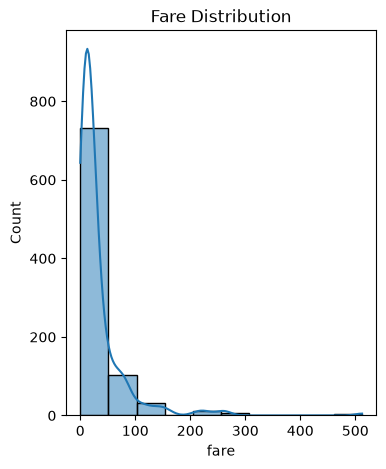

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(4,5))
sns.histplot(df["age"],bins=10,kde=True)
plt.title("Age Distribution")
plt.show()

plt.figure(figsize=(4,5))
sns.histplot(df["fare"],bins=10,kde=True)
plt.title("Fare Distribution")
plt.show()

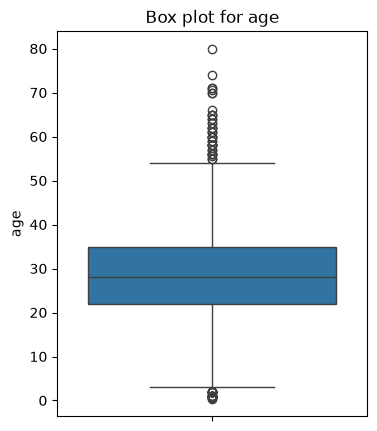

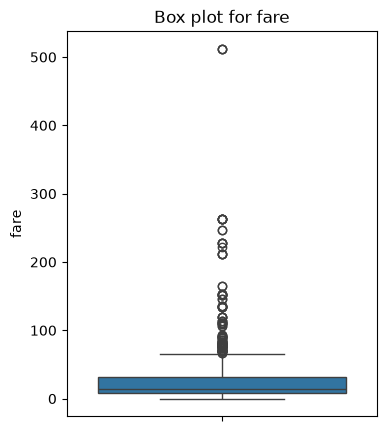

In [12]:
plt.figure(figsize=(4,5))
sns.boxplot(df["age"])
plt.title("Box plot for age")
plt.show()

plt.figure(figsize=(4,5))
sns.boxplot(df["fare"])
plt.title("Box plot for fare")
plt.show()

Finding otlliers using IQR rule

In [13]:
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

IQR = Q3-Q1

lower = Q1-1.5*IQR
upper = Q3-1.5*IQR

age_outliers=df[(df["age"]<lower) | (df["age"]>upper)]
print(age_outliers[["age"]])
print("No.of outliers:",len(age_outliers))

Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)

IQR = Q3-Q1

lower = Q1-1.5*IQR
upper = Q3-1.5*IQR

fare_outliers=df[(df["fare"]<lower) | (df["fare"]>upper)]
print(fare_outliers[["fare"]])
print("No.of outliers:",len(fare_outliers))



      age
0    22.0
1    38.0
2    26.0
3    35.0
4    35.0
..    ...
886  27.0
887  19.0
888  28.0
889  26.0
890  32.0

[830 rows x 1 columns]
No.of outliers: 830
        fare
0     7.2500
1    71.2833
2     7.9250
3    53.1000
4     8.0500
..       ...
886  13.0000
887  30.0000
888  23.4500
889  30.0000
890   7.7500

[889 rows x 1 columns]
No.of outliers: 889


Mean ,Median,Mode of fare

In [14]:
mean = df["fare"].mean()
median = df["fare"].median()
mode = df["fare"].mode()[0]

print("Mean:",mean)
print("Median:",median)
print("Mode:",mode)

Mean: 32.09668087739032
Median: 14.4542
Mode: 8.05


the fare distribuion is right skewed because mean is greater than median ,median greater than mode.

Bivarent Analysis

survival rate by sex

In [15]:
female_survival = df[df["sex"]=="female"]["survived"].mean()*100
male_survival = df[df["sex"]=="male"]["survived"].mean()*100
print("Female:",female_survival)
print("Male:",male_survival)

Female: 74.03846153846155
Male: 18.890814558058924


survival rate by pclass

In [16]:
for cls in [1,2,3]:
    rate = df[df["pclass"]==cls]["survived"].mean()*100
    print(cls,rate)

1 62.616822429906534
2 47.28260869565217
3 24.236252545824847


survival rate by sex and pclass

In [17]:
for sex in ["male","female"]:
    for cls in [1,2,3]:
        rate = df[
            (df["sex"]==sex)
            &
            (df["pclass"]==cls)]["survived"].mean()*100
        print(sex,cls,rate)
        

male 1 36.885245901639344
male 2 15.74074074074074
male 3 13.544668587896252
female 1 96.73913043478261
female 2 92.10526315789474
female 3 50.0


Correlation

In [18]:
columns = [
    "survived",
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]
corr = df[columns].corr()
print(corr)

          survived    pclass       age     sibsp     parch      fare
survived  1.000000 -0.335549 -0.069822 -0.034040  0.083151  0.255290
pclass   -0.335549  1.000000 -0.336512  0.081656  0.016824 -0.548193
age      -0.069822 -0.336512  1.000000 -0.232543 -0.171485  0.093707
sibsp    -0.034040  0.081656 -0.232543  1.000000  0.414542  0.160887
parch     0.083151  0.016824 -0.171485  0.414542  1.000000  0.217532
fare      0.255290 -0.548193  0.093707  0.160887  0.217532  1.000000


HeatMap

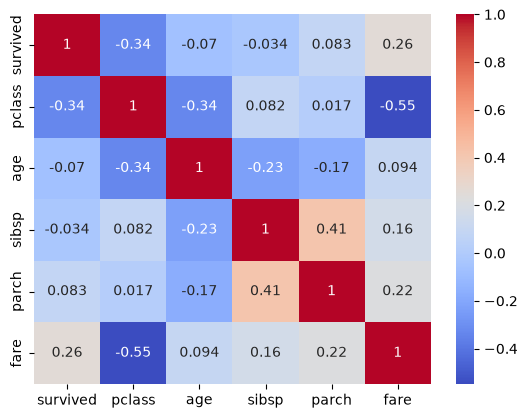

In [19]:
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)
plt.show()

In [20]:
pairs = []

for i in range(len(corr.columns)):
    for j in range(i):
        pairs.append((corr.columns[i], corr.columns[j], corr.iloc[i, j]))

pairs = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)

print("Top 2 Strongest Correlations:")
for pair in pairs[:2]:
    print(pair)

Top 2 Strongest Correlations:
('fare', 'pclass', np.float64(-0.5481932852366449))
('parch', 'sibsp', np.float64(0.4145416380997264))


The strongest correlation is between fare and pclass with a correlation coefficient of -0.548. This indicates a moderate negative correlation, meaning that passengers in lower class numbers (First Class = 1) generally paid higher fares, while passengers in higher class numbers (Third Class = 3) generally paid lower fares.

The second strongest correlation is between parch and sibsp with a correlation coefficient of 0.415. This indicates a moderate positive correlation, suggesting that passengers travelling with siblings/spouses were also more likely to be travelling with parents/children.

Multivarent data story

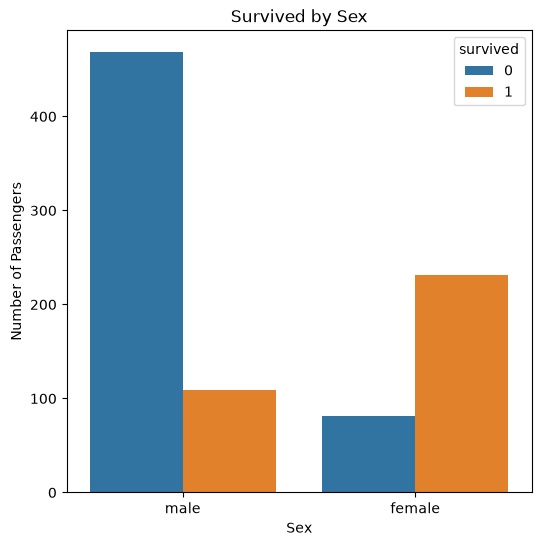

In [21]:
plt.figure(figsize=(6,6))
sns.countplot(x="sex",hue="survived",data=df)
plt.title("Survived by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")

plt.show()

The chart shows that the female passengers has much survival rate than the male passengers.Most of the femal survived but male are less survived this shows that gender played a significent role in survival rate

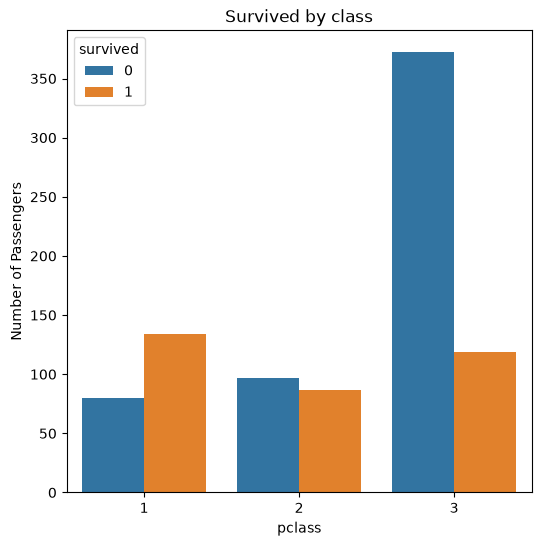

In [22]:
plt.figure(figsize=(6,6))
sns.countplot(x="pclass",hue="survived",data=df)
plt.title("Survived by class")
plt.xlabel("pclass")
plt.ylabel("Number of Passengers")

plt.show()